# 전법인 서비스 부품 | 출시 후 18주 수요 프로파일

운영 자재 마스터와 수요 상세를 연결해, 법인·사이트별 품목마다 **18주 수요량**과 **18주 총량 대비 주별 비중**을 만든다. 수요 기록이 있고 그 합이 0인 주와 수요량을 알 수 없는 주를 구분한다. 이어서 출시일 기준으로 분할하고 K-means로 대표 패턴을 찾는다. 마지막에는 출시 시점 속성으로 패턴과 18주 총수요를 따로 예측하고, 두 예측을 주별 수요로 결합한다.

> 개발 DB에서 추출한 실험용 데이터다. 수요 상세 대부분에 합성 생성 표식이 있으며, 현재 마스터의 `sell_start_dt`는 출시 주차를 정렬하기 위한 기준일이다. 실제 출시일이나 출시 당시의 마스터 속성이 별도로 확인된 것은 아니다.

## 1. 입력과 처리 기준

- 입력: `raw_data/ltb_new_product_profiles/tb_mst_oper_part.parquet` 및 `demand_detail_2018W01_2025W44/<법인>/<연도>.parquet`. 두 Manifest에 출처, 범위, 건수가 기록돼 있다. DB에는 접속하지 않는다.
- 조인: `company_cd + subs_cd + site_cd + part_no` (마스터는 `oper_part_no`). 같은 품목번호라도 조직 키가 다르면 별도 프로파일이다.
- 시간축: 판매 시작일이 속한 ISO 주차의 월요일이 **1주차**, 그로부터 17주 뒤가 **18주차**다. 원천 `order_dt`도 ISO 주차 시작일인지 확인한 뒤 연결한다. 첫 양수 수요를 출시일 대신 사용하지 않는다.
- 수량: `del_flag='Y'`는 집계에서 제외하되 건수는 보존한다. 그 외 주문유형을 합산하고 `close_flag`는 필터로 쓰지 않는다. NULL 수량이나 마스터와 맞지 않는 단위가 섞인 주는 합계 품질을 보장할 수 없어 결측 처리한다.
- 정규화: 18주 모두 수량을 알 수 있고 주간 합계가 모두 음수가 아니며 18주 총수요가 양수일 때만 `profile_share = weekly_demand_qty / total_demand_18w`를 계산한다. 전부 0인 프로파일은 주별 수요량은 보존하되 비중을 만들지 않는다.

커널: **Python (ts_forecaster)**. 기본 실행은 결과를 화면에만 표시한다. 파일을 생성하려면 경로 및 저장 설정을 아래에서 조정한다. 기존 결과 폴더는 덮어쓰지 않는다.

In [1]:
from datetime import datetime
import json
import os
from pathlib import Path
import tempfile

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import polars as pl

get_ipython().run_line_magic("matplotlib", "inline")

KEY = ["company_cd", "subs_cd", "site_cd", "part_no"]
JOIN_KEY = KEY + ["week_start"]
HORIZON = 18
DATASET_NAME = "ltb_new_product_profiles"
EXTRACT_NAME = "demand_detail_2018W01_2025W44"


def resolve_data_dir():
    override = os.environ.get("TS_FORECASTER_ROOT")
    roots = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        folder = root / "raw_data" / DATASET_NAME
        if (folder / "tb_mst_oper_part.parquet").is_file():
            return folder
    raise FileNotFoundError("ts_forecaster_lib 아래에서 실행하거나 TS_FORECASTER_ROOT를 지정하세요.")


data_dir = resolve_data_dir()
extract_dir = data_dir / EXTRACT_NAME
manifest = json.loads((extract_dir / "manifest.json").read_text())
master_manifest = json.loads((data_dir / "manifest.json").read_text())
write_artifacts = os.environ.get("LTB_WRITE_PROFILES", "0") == "1"
output_dir = Path(os.environ.get("LTB_PROFILE_OUTPUT_DIR", str(data_dir / "launch_profiles_18w_v1")))


def parse_date_key(value):
    return datetime.strptime(value, "%Y%m%d").date()


extract_from = parse_date_key(manifest["order_dt_from_inclusive"])
extract_until = parse_date_key(manifest["order_dt_until_exclusive"])
assert extract_from.weekday() == extract_until.weekday() == 0

### 마스터 조인 키와 원천 주차 확인

생활주기 단계나 구매 시점 관련 파생값은 출시 전 예측에 바로 쓰지 않는다. 비교용으로 현재 자재 분류만 요약 파일에 남긴다.

In [2]:
master = (
    pl.read_parquet(
        data_dir / "tb_mst_oper_part.parquet",
        columns=KEY[:-1] + [
            "oper_part_no", "sell_start_dt", "demand_start_dt", "part_reg_dt",
            "unit", "part_fam_cd", "mat_type", "prod_type", "prod_grp",
        ],
    )
    .rename({"oper_part_no": "part_no", "sell_start_dt": "launch_date", "unit": "master_unit"})
    .with_columns(pl.col("launch_date").dt.truncate("1w").alias("launch_week_start"))
)
assert master.height == master_manifest["row_count"]
assert master.select(pl.struct(KEY).n_unique()).item() == master.height
assert not master.select(pl.any_horizontal(pl.col(KEY).is_null()).any()).item()

extract_paths = [extract_dir / item["path"] for item in manifest["files"]]
raw_all = pl.scan_parquet(extract_paths)
assert raw_all.select(pl.len()).collect().item() == manifest["total_rows"]
source_weeks = (
    raw_all.select(pl.col("order_dt").unique().str.strptime(pl.Date, "%Y%m%d", strict=True).alias("week_start"))
    .collect(engine="streaming")
    .sort("week_start")
)
assert source_weeks["week_start"].null_count() == 0
assert source_weeks.filter(
    (pl.col("week_start").dt.weekday() != 1)
    | (pl.col("week_start") < extract_from)
    | (pl.col("week_start") >= extract_until)
).is_empty(), "이 Notebook은 주차 시작일이 담긴 수요 추출본을 대상으로 한다."

display(Markdown(
    f"마스터 **{master.height:,}개 조직·품목**, 수요 상세 **{manifest['total_rows']:,}행**, "
    f"수요 기록이 있는 ISO 주차 **{source_weeks.height:,}개**. "
    f"수요 상세의 합성 생성 표식 비율: **{manifest['total_synthetic_marker_rows'] / manifest['total_rows']:.2%}**."
))
same_launch_week = master.select(
    (pl.col("launch_date").dt.strftime("%G%V").cast(pl.Int32) == pl.col("demand_start_dt")).sum()
).item()
display(Markdown(
    f"판매 시작 주차가 수요 시작 주차와 일치하는 품목: **{same_launch_week:,}/{master.height:,}**. "
    "두 필드가 일치해도 실제 출시일을 독립적으로 검증한 것은 아니다."
))

마스터 **350,000개 조직·품목**, 수요 상세 **114,549,275행**, 수요 기록이 있는 ISO 주차 **409개**. 수요 상세의 합성 생성 표식 비율: **99.95%**.

판매 시작 주차가 수요 시작 주차와 일치하는 품목: **350,000/350,000**. 두 필드가 일치해도 실제 출시일을 독립적으로 검증한 것은 아니다.

## 2. 출시 주차에 맞춰 수요 연결

품목별 18주 달력을 먼저 만든다. 원천 행이 없어도 달력에는 주차가 남는다.

| 주차 상태 | 수요량 | 의미 |
| --- | --- | --- |
| `observed_positive` / `observed_negative` | 실제 저장된 합계 | 조건을 충족하는 원천 기록이 있음 |
| `observed_zero` | 0 | 조건을 충족하는 원천 기록의 주간 합계가 0 |
| `no_source_row` | NULL | 추출 기간 안이지만 그 품목·주차 원천 행이 없음 |
| `outside_extract_window` | NULL | 추출 기간 밖이라 해당 주를 확인할 수 없음 |
| `only_deleted_rows` | NULL | 원천 행은 있으나 삭제되지 않은 행은 없음 |
| `incomplete_quantity` / `unit_mismatch` | NULL | 수량 누락 또는 단위 불일치로 합계 사용 불가 |

출시일이 없는 품목은 주차 달력 대신 품목별 요약에 `no_launch_date`로 남긴다.

In [3]:
def build_week_grid(launch_master):
    return (
        launch_master.filter(pl.col("launch_week_start").is_not_null())
        .select(KEY + ["launch_date", "launch_week_start", "master_unit"])
        .with_columns(pl.int_ranges(1, HORIZON + 1, dtype=pl.Int8).alias("week_no"))
        .explode("week_no")
        .with_columns(
            (pl.col("launch_week_start") + pl.duration(weeks=pl.col("week_no").cast(pl.Int64) - 1))
            .cast(pl.Date).alias("week_start")
        )
        .with_columns(
            pl.col("week_start").is_between(extract_from, extract_until, closed="left")
            .alias("in_extract_window"),
            pl.col("week_start").dt.strftime("%Y%m%d").alias("order_dt"),
        )
    )


def build_weekly_demand(grid, demand):
    scope_dates = grid.filter(pl.col("in_extract_window")).select(
        KEY + ["order_dt", "master_unit"]
    )
    accepted = pl.col("del_flag").fill_null("N") != "Y"
    qty = pl.col("order_qty")
    unit_match = (
        (pl.col("qty_uom") == pl.col("master_unit"))
        & pl.col("master_unit").str.strip_chars().ne("")
    ).fill_null(False)
    weekly = (
        demand.select(KEY + ["order_dt", "order_qty", "qty_uom", "del_flag"])
        .join(scope_dates.lazy(), on=KEY + ["order_dt"], how="inner")
        .group_by(KEY + ["order_dt"])
        .agg(
            pl.len().alias("source_rows"),
            accepted.sum().alias("included_rows"),
            (accepted & qty.is_not_null()).sum().alias("nonnull_qty_rows"),
            (accepted & ~unit_match).sum().alias("unit_mismatch_rows"),
            qty.filter(accepted).sum().alias("included_qty_sum"),
        )
        .collect(engine="streaming")
    )
    counts = ["source_rows", "included_rows", "nonnull_qty_rows", "unit_mismatch_rows"]
    joined = grid.join(weekly, on=KEY + ["order_dt"], how="left", validate="1:1").with_columns(
        pl.col(counts).fill_null(0)
    )
    return (
        joined.with_columns(
            pl.when(~pl.col("in_extract_window")).then(pl.lit("outside_extract_window"))
            .when(pl.col("source_rows") == 0).then(pl.lit("no_source_row"))
            .when(pl.col("included_rows") == 0).then(pl.lit("only_deleted_rows"))
            .when(pl.col("nonnull_qty_rows") != pl.col("included_rows")).then(pl.lit("incomplete_quantity"))
            .when(pl.col("unit_mismatch_rows") > 0).then(pl.lit("unit_mismatch"))
            .when(pl.col("included_qty_sum") == 0).then(pl.lit("observed_zero"))
            .when(pl.col("included_qty_sum") < 0).then(pl.lit("observed_negative"))
            .otherwise(pl.lit("observed_positive"))
            .alias("week_status")
        )
        .with_columns(
            pl.when(pl.col("week_status").str.starts_with("observed_"))
            .then(pl.col("included_qty_sum")).otherwise(None).alias("weekly_demand_qty")
        )
        .drop("included_qty_sum", "order_dt")
    )


def build_item_profiles(launch_master, weekly):
    stats = weekly.group_by(KEY).agg(
        pl.col("weekly_demand_qty").is_not_null().sum().alias("observed_weeks"),
        (pl.col("week_status") == "observed_zero").sum().alias("zero_weeks"),
        (pl.col("week_status") == "observed_negative").sum().alias("negative_weeks"),
        (pl.col("week_status") == "no_source_row").sum().alias("no_source_weeks"),
        (~pl.col("in_extract_window")).sum().alias("out_of_window_weeks"),
        pl.col("weekly_demand_qty").sum().alias("observed_demand_sum"),
    )
    summary = (
        launch_master.join(stats, on=KEY, how="left", validate="1:1")
        .with_columns(
            (HORIZON - pl.col("observed_weeks")).alias("missing_weeks"),
            pl.when(pl.col("observed_weeks") == HORIZON)
            .then(pl.col("observed_demand_sum")).otherwise(None).alias("total_demand_18w"),
        )
        .with_columns(
            pl.when(pl.col("launch_date").is_null()).then(pl.lit("no_launch_date"))
            .when(pl.col("observed_weeks") < HORIZON).then(pl.lit("incomplete_18w"))
            .when(pl.col("negative_weeks") > 0).then(pl.lit("negative_week"))
            .when(pl.col("total_demand_18w") == 0).then(pl.lit("all_zero"))
            .otherwise(pl.lit("ready")).alias("profile_status"),
        )
        .drop("observed_demand_sum")
    )
    long = (
        weekly.join(summary.select(KEY + ["profile_status", "total_demand_18w"]), on=KEY, validate="m:1")
        .with_columns(
            pl.when(pl.col("profile_status") == "ready")
            .then(pl.col("weekly_demand_qty").cast(pl.Float64) / pl.col("total_demand_18w").cast(pl.Float64))
            .otherwise(None).alias("profile_share")
        )
    )
    vectors = (
        long.filter(pl.col("profile_status") == "ready")
        .group_by(KEY)
        .agg(
            pl.col("launch_date").first(),
            pl.col("launch_week_start").first(),
            pl.col("master_unit").first(),
            pl.col("total_demand_18w").first(),
            pl.col("weekly_demand_qty").sort_by("week_no").alias("weekly_demand_1_to_18"),
            pl.col("profile_share").sort_by("week_no").alias("profile_share_1_to_18"),
        )
    )
    return long, summary, vectors

### 경계 상황 검증

아래는 변환 규칙만 검증하기 위한 작은 테스트다. 집계 결과나 그래프에 포함되지 않는다.

In [4]:
from datetime import timedelta
from decimal import Decimal

test_master = pl.DataFrame({
    **dict(zip(KEY, [["TEST"], ["TEST"], ["TEST"], ["part"]])),
    "launch_date": [extract_from - timedelta(weeks=1)],
    "launch_week_start": [extract_from - timedelta(weeks=1)],
    "master_unit": ["EA"],
})
test_cases = [
    (0, "0", "EA", "N"),                         # 2주차: 원천 0
    (2, "9", "EA", "Y"),                         # 4주차: 삭제 행만 있음
    (3, None, "EA", "N"),                        # 5주차: NULL 수량
    (4, "3", "EA", "N"), (4, "2", "EA", "N"),     # 6주차: 2건 합산
    (5, "7", "BOX", "N"),                        # 7주차: 단위 불일치
    (6, "-1", "EA", None),                       # 8주차: 유효 음수
]
test_demand = pl.DataFrame({
    **{key: [test_master[key][0]] * len(test_cases) for key in KEY},
    "order_dt": [(extract_from + timedelta(weeks=k)).strftime("%Y%m%d") for k, *_ in test_cases],
    "order_qty": pl.Series([Decimal(v) if v is not None else None for _, v, _, _ in test_cases],
                           dtype=pl.Decimal(15, 3)),
    "qty_uom": [u for _, _, u, _ in test_cases],
    "del_flag": [d for _, _, _, d in test_cases],
}).lazy()
test_weekly = build_weekly_demand(build_week_grid(test_master), test_demand).sort("week_no")
assert test_weekly.height == HORIZON
assert test_weekly["week_status"].head(8).to_list() == [
    "outside_extract_window", "observed_zero", "no_source_row", "only_deleted_rows",
    "incomplete_quantity", "observed_positive", "unit_mismatch", "observed_negative",
]
assert test_weekly["weekly_demand_qty"].head(8).to_list() == [None, 0, None, None, None, 5, None, -1]
_, test_summary, test_vectors = build_item_profiles(test_master, test_weekly)
assert test_summary["profile_status"][0] == "incomplete_18w"
assert test_summary["total_demand_18w"][0] is None and test_vectors.is_empty()
print("통과: 0 수요, 누락, 기간 밖, 삭제, NULL, 주문 합산, 단위 불일치, 음수 구분")

통과: 0 수요, 누락, 기간 밖, 삭제, NULL, 주문 합산, 단위 불일치, 음수 구분


## 3. 전법인 프로파일 생성

법인별로 나누어 읽고, 전체 원천을 한 번에 메모리에 올리지 않는다. 저장 설정을 켠 경우 결과만 Parquet으로 내보낸다.

In [5]:
subsidiaries = sorted(master["subs_cd"].unique().to_list())
assert set(subsidiaries) == set(manifest["by_subsidiary"])
week_count_pieces = []
item_count_pieces = []
vector_check_pieces = []
file_records = []
clustering_input_pieces = []
forecast_input_pieces = []
if write_artifacts and output_dir.exists():
    raise FileExistsError(f"{output_dir.name} 폴더가 이미 있습니다. 다른 출력 경로를 지정하세요.")


def run_one_subsidiary(subsidiary, staged_folder):
    sub_master = master.filter(pl.col("subs_cd") == subsidiary)
    sub_files = [p for p in extract_paths if p.parent.name == subsidiary]
    grid = build_week_grid(sub_master)
    demand = pl.scan_parquet(sub_files)
    weekly = build_weekly_demand(grid, demand)
    long, summary, vectors = build_item_profiles(sub_master, weekly)

    assert long.height == (sub_master.height - sub_master["launch_date"].null_count()) * HORIZON
    assert long.select(pl.struct(JOIN_KEY).n_unique()).item() == long.height
    assert summary.height == sub_master.height
    assert long.filter(
        ((pl.col("week_status") == "observed_zero") & (pl.col("weekly_demand_qty") != 0).fill_null(True))
        | (~pl.col("week_status").str.starts_with("observed_") & pl.col("weekly_demand_qty").is_not_null())
        | (pl.col("week_status").str.starts_with("observed_") & pl.col("weekly_demand_qty").is_null())
    ).is_empty()
    assert vectors.height == summary.filter(pl.col("profile_status") == "ready").height
    assert vectors.filter(
        (pl.col("weekly_demand_1_to_18").list.len() != HORIZON)
        | (pl.col("profile_share_1_to_18").list.len() != HORIZON)
        | ((pl.col("profile_share_1_to_18").list.sum() - 1.0).abs() > 1e-9)
    ).is_empty()

    if staged_folder is not None:
        folder = staged_folder / subsidiary
        folder.mkdir()
        for name, frame in [
            ("weekly_profiles", long.sort(KEY + ["week_no"])),
            ("item_summary", summary.sort(KEY)),
            ("ready_vectors", vectors.sort(KEY)),
        ]:
            path = folder / f"{name}.parquet"
            frame.write_parquet(path, compression="zstd")
            assert pl.scan_parquet(path).select(pl.len()).collect().item() == frame.height
            file_records.append({"file": str(path.relative_to(staged_folder)), "rows": frame.height})

    week_count_pieces.append(
        long.group_by(["week_no", "week_status"])
        .agg(pl.len().alias("rows"), pl.col("profile_share").sum().alias("share_sum"))
    )
    item_count_pieces.append(summary.group_by(["subs_cd", "profile_status"]).len())
    forecast_cohort = summary.filter(pl.col("profile_status").is_in(["ready", "all_zero"])).select(
        KEY + ["launch_date", "launch_week_start", "part_fam_cd", "prod_type", "prod_grp", "profile_status"]
    )
    observed_vectors = weekly.select(KEY + ["week_no", "weekly_demand_qty"]).group_by(KEY).agg(
        pl.col("weekly_demand_qty").cast(pl.Float64).sort_by("week_no").alias("weekly_actual")
    )
    forecast_input_pieces.append(
        forecast_cohort.join(observed_vectors, on=KEY, how="left", validate="1:1")
    )
    vector_check_pieces.append(vectors.height)
    clustering_input_pieces.append(
        vectors.select(KEY + ["launch_date", "launch_week_start", "profile_share_1_to_18"])
    )


def run_all(staged_folder):
    for subsidiary in subsidiaries:
        run_one_subsidiary(subsidiary, staged_folder)


if write_artifacts:
    output_dir.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".ltb_profiles_", dir=output_dir.parent) as tmp:
        stage = Path(tmp) / "dataset"
        stage.mkdir()
        run_all(stage)
        metadata = {
            "inputs": ["manifest.json", f"{EXTRACT_NAME}/manifest.json"],
            "source_master_sha256": manifest["master_parquet_sha256"],
            "source_detail_snapshot_at_utc": manifest["source_snapshot_at_utc"],
            "join_key": KEY,
            "launch_anchor": "sell_start_dt, ISO Monday",
            "week_numbers": [1, HORIZON],
            "source_filters": "Exclude del_flag=Y from sums; no close_flag or order-type filter",
            "missing_policy": "Keep unknown or unavailable weeks NULL; retain observed 0",
            "normalization": "Only complete, nonnegative profiles with positive total",
            "files": file_records,
        }
        (stage / "manifest.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
        if output_dir.exists():
            raise FileExistsError("Output folder appeared during processing.")
        stage.rename(output_dir)
else:
    run_all(None)

## 4. 결과

분모는 전체 자재 수가 아니라 **출시 기준일이 있는 조직·품목의 18개 주차**다. 정규화 프로파일의 평균은 분석 가능 품목을 같은 비중으로 반영한다.

In [6]:
item_counts = (
    pl.concat(item_count_pieces).group_by("profile_status").agg(pl.col("len").sum().alias("items"))
    .sort("items", descending=True)
)
all_weeks = (
    pl.concat(week_count_pieces).group_by(["week_no", "week_status"])
    .agg(pl.col("rows").sum(), pl.col("share_sum").sum())
    .sort(["week_no", "week_status"])
)
assert item_counts["items"].sum() == master.height
assert all_weeks["rows"].sum() == (master.height - master["launch_date"].null_count()) * HORIZON

ready = sum(vector_check_pieces)
zeros = all_weeks.filter(pl.col("week_status") == "observed_zero")["rows"].sum()
missing = all_weeks.filter(~pl.col("week_status").str.starts_with("observed_"))["rows"].sum()
display(Markdown(
    f"**{master.height:,}개 조직·품목 → {all_weeks['rows'].sum():,}개 품목·주차.** "
    f"기록된 0수요 **{zeros:,}주**, 결측 **{missing:,}주**. "
    f"18주 정규화 프로파일 **{ready:,}개**."
))
status_labels = {
    "ready": "정규화 프로파일 생성",
    "all_zero": "18주 모두 0수요",
    "incomplete_18w": "18주 중 결측 있음",
    "negative_week": "음수 합계 주차 있음",
    "no_launch_date": "출시일 없음",
}
display(Markdown("\n".join(
    ["| 품목 기준 판정 | 조직·품목 수 |", "|---|---:|"]
    + [
        f"| {label} | {dict(item_counts.iter_rows()).get(status, 0):,} |"
        for status, label in status_labels.items()
    ]
)))

**350,000개 조직·품목 → 6,300,000개 품목·주차.** 기록된 0수요 **4,234,241주**, 결측 **0주**. 18주 정규화 프로파일 **328,750개**.

| 품목 기준 판정 | 조직·품목 수 |
|---|---:|
| 정규화 프로파일 생성 | 328,750 |
| 18주 모두 0수요 | 21,250 |
| 18주 중 결측 있음 | 0 |
| 음수 합계 주차 있음 | 0 |
| 출시일 없음 | 0 |

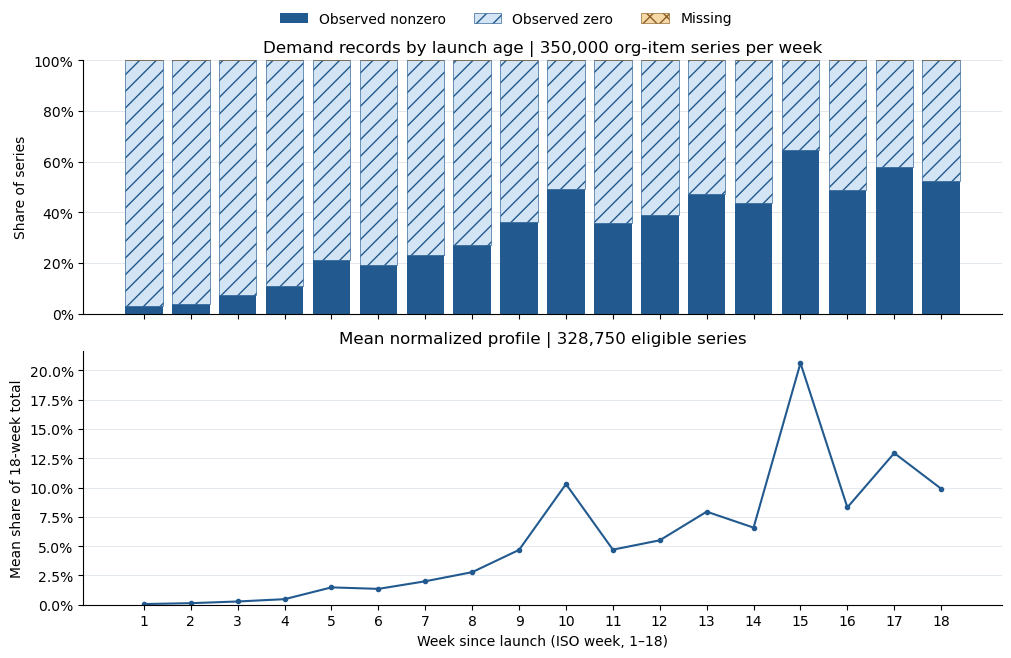

In [7]:
all_counts = {(week, status): rows for week, status, rows, _ in all_weeks.iter_rows()}
week_numbers = list(range(1, HORIZON + 1))
nonzero = [sum(all_counts.get((w, s), 0) for s in ("observed_positive", "observed_negative")) for w in week_numbers]
zero = [all_counts.get((w, "observed_zero"), 0) for w in week_numbers]
denom = master.height - master["launch_date"].null_count()
missing_by_week = [denom - a - b for a, b in zip(nonzero, zero)]

fig, (ax, profile_ax) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, layout="constrained")
ax.bar(week_numbers, [v / denom for v in nonzero], color="#225a8f", label="Observed nonzero")
ax.bar(
    week_numbers, [v / denom for v in zero], bottom=[v / denom for v in nonzero],
    facecolor="#d3e5f5", edgecolor="#225a8f", linewidth=0.45, hatch="//", label="Observed zero",
)
ax.bar(
    week_numbers, [v / denom for v in missing_by_week], bottom=[(a + b) / denom for a, b in zip(nonzero, zero)],
    facecolor="#f4d8a5", edgecolor="#8b5e27", linewidth=0.45, hatch="xx", label="Missing",
)
ax.set(title=f"Demand records by launch age | {denom:,} org-item series per week", ylabel="Share of series", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncols=3, frameon=False)

if ready:
    mean_profile = all_weeks.group_by("week_no").agg(
        (pl.col("share_sum").sum() / ready).alias("average_share")
    ).sort("week_no")
    assert abs(mean_profile["average_share"].sum() - 1.0) < 1e-9
    profile_ax.plot(
        mean_profile["week_no"].to_list(), mean_profile["average_share"].to_list(),
        marker="o", markersize=3, color="#225a8f",
    )
    profile_ax.set(title=f"Mean normalized profile | {ready:,} eligible series", ylim=(0, None))
else:
    profile_ax.set_title("Mean normalized profile | No eligible series")
profile_ax.set(ylabel="Mean share of 18-week total", xlabel="Week since launch (ISO week, 1–18)")
profile_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
profile_ax.set_xticks(week_numbers)
for axis in (ax, profile_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#dde4eb", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. 다음 실험에 사용할 파일

저장 옵션을 켜면 `raw_data/ltb_new_product_profiles/launch_profiles_18w_v1/<법인>/`에 아래 파일이 생긴다.

- `weekly_profiles.parquet`: 품목·출시 후 주차별 수요량, 상태, 원천 건수, 비중
- `item_summary.parquet`: 품목별 출시일, 18주 총수요, 0수요·결측 주차 수, 사용 가능 여부 및 현재 마스터 속성
- `ready_vectors.parquet`: 18주 수요와 비중을 1–18주 순서로 저장한 리스트. 후속 실험에서는 이 벡터를 사용하되 시간 기준 학습·검증 분할을 먼저 하고, 군집 중심은 학습 표본에만 맞춘다.

데이터의 출처와 명세는 함께 생성된 `manifest.json`에 기록한다. 원천 파일은 수정하지 않는다.

## 6. 출시 시점으로 학습·검증 분리

- **기준일: 2020년 ISO 1주차(2019-12-30)**. 2018·2019년 초 출시 구간과 이후 출시 구간을 분리한다. 전체에서 약 75:25가 되는 달력 경계를 선택했고, 수요 패턴이나 검증 지표를 보고 날짜를 고르지 않았다.
- **학습**: 기준일보다 먼저 출시했고 18주차가 기준일까지 끝난 조직·품목. 결과가 알려지는 가장 빠른 날짜를 `launch_week_start + 18주`로 둔다.
- **검증**: 기준일 이후(포함) 출시 품목. 기준일 전에 출시했지만 18주가 아직 끝나지 않은 품목은 학습과 검증 양쪽에서 뺀다.
- 앞 단계에서 정규화할 수 있었던 프로파일만 사용한다. 전부 0인 품목과 결측이 있는 품목을 패턴에 강제로 배정하지 않는다.

In [8]:
from datetime import date
import numpy as np
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from threadpoolctl import threadpool_limits

CUTOFF = date.fromisocalendar(2020, 1, 1)
SEED = 20261124
CANDIDATE_K = tuple(range(2, 9))
RESTARTS = 25
SCREEN_FIT_MAX = 24_000
SCREEN_SCORE_MAX = 3_000
THREADS = 4
PROFILE_COLUMN = "profile_share_1_to_18"

profiles_for_cluster = (
    pl.concat(clustering_input_pieces)
    .sort(["launch_date", *KEY])
    .with_columns(
        (pl.col("launch_week_start") + pl.duration(weeks=HORIZON)).cast(pl.Date).alias("label_available_on")
    )
    .with_columns(
        pl.when(pl.col("launch_date") >= CUTOFF).then(pl.lit("validation"))
        .when(pl.col("label_available_on") <= CUTOFF).then(pl.lit("train"))
        .otherwise(pl.lit("gap"))
        .alias("split")
    )
)
assert profiles_for_cluster.height == ready
assert profiles_for_cluster.select(pl.struct(KEY).n_unique()).item() == ready
assert profiles_for_cluster.group_by("launch_date").agg(pl.col("split").n_unique())["split"].max() == 1
split_counts = dict(profiles_for_cluster.group_by("split").len().iter_rows())
train_set = profiles_for_cluster.filter(pl.col("split") == "train")
validation_set = profiles_for_cluster.filter(pl.col("split") == "validation")
assert train_set.height > max(CANDIDATE_K) and validation_set.height > 0
assert train_set["label_available_on"].max() <= CUTOFF
assert train_set["launch_date"].max() < CUTOFF <= validation_set["launch_date"].min()
assert sum(split_counts.values()) == ready

shared_part_numbers = train_set.select("part_no").unique().join(
    validation_set.select("part_no").unique(), on="part_no", how="inner"
).height
display(Markdown("\n".join([
    "| 집합 | 조직·품목 수 | 실제 출시일 범위 |",
    "|---|---:|---|",
    f"| 학습 | {train_set.height:,} | {train_set['launch_date'].min()} ~ {train_set['launch_date'].max()} |",
    f"| 검증 | {validation_set.height:,} | {validation_set['launch_date'].min()} ~ {validation_set['launch_date'].max()} |",
    f"| 18주 미완료로 제외 | {split_counts.get('gap', 0):,} | 기준일 전 출시, 18주 미종료 |",
])))
display(Markdown(
    f"양쪽에 공통으로 나타난 **품목번호는 {shared_part_numbers:,}개**다. "
    "회사·법인·사이트·품목번호 전체 조합은 겹치지 않지만, 다른 조직에서 출시된 동일 품목은 남는다. "
    "이 검증은 새 조직·품목의 시간 순서 검증이며, 완전히 새로운 품목번호에 대한 검증은 아니다."
))

| 집합 | 조직·품목 수 | 실제 출시일 범위 |
|---|---:|---|
| 학습 | 241,908 | 2018-01-01 ~ 2019-03-25 |
| 검증 | 86,842 | 2019-12-30 ~ 2023-03-27 |
| 18주 미완료로 제외 | 0 | 기준일 전 출시, 18주 미종료 |

양쪽에 공통으로 나타난 **품목번호는 21,192개**다. 회사·법인·사이트·품목번호 전체 조합은 겹치지 않지만, 다른 조직에서 출시된 동일 품목은 남는다. 이 검증은 새 조직·품목의 시간 순서 검증이며, 완전히 새로운 품목번호에 대한 검증은 아니다.

## 7. 군집 수 선택과 학습

논문 노트의 K-means 절차를 참고해 `K=2~8`을 비교한다. **후보마다 동일한 학습 표본**에서 25회 초기화로 적합하고, 공통 학습 평가 표본에서 Davies–Bouldin(낮을수록 좋음), Silhouette·Calinski–Harabasz(높을수록 좋음)를 계산한다. 지표별 1위에 한 표씩 주고, 동률이면 세 지표 평균 순위, 그래도 같으면 작은 K를 선택한다.

맥북에서 반복 실행할 수 있도록 후보 탐색은 학습 데이터 최대 24,000개(평가 최대 3,000개)로 제한한다. **선택된 K는 학습 데이터 전체에 다시 25회 초기화로 적합**한다. 검증 데이터는 군집 수 선택과 중심 계산에 사용하지 않는다. 주별 비중 벡터를 그대로 사용해 정규화된 수요 모양을 비교하고, 주차별 표준화는 적용하지 않는다. 이 시간 분할과 표본 제한은 이번 실험의 설정이다.

In [9]:
def matrix_for(frame):
    x = frame.select(pl.col(PROFILE_COLUMN).list.to_array(HORIZON)).to_series().to_numpy()
    x = np.ascontiguousarray(x, dtype=np.float64)
    assert x.shape == (frame.height, HORIZON)
    assert np.isfinite(x).all() and (x >= 0.0).all() and np.allclose(x.sum(axis=1), 1.0, atol=1e-9, rtol=0)
    return x


def build_kmeans(k, *, tol=1e-4):
    return KMeans(
        n_clusters=k, init="k-means++", n_init=RESTARTS,
        random_state=SEED, algorithm="lloyd", max_iter=300, tol=tol,
    )


x_train = matrix_for(train_set)
rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(x_train))
fit_size = min(SCREEN_FIT_MAX, max(max(CANDIDATE_K), int(0.85 * len(x_train))))
fit_indices = permutation[:fit_size]
score_indices = permutation[fit_size:fit_size + SCREEN_SCORE_MAX]
assert len(score_indices) > max(CANDIDATE_K)
screen_fit = x_train[fit_indices]
screen_score = x_train[score_indices]

metrics = []
with threadpool_limits(limits=THREADS):
    for k in CANDIDATE_K:
        screened_model = build_kmeans(k).fit(screen_fit)
        score_labels = screened_model.predict(screen_score)
        if len(np.unique(score_labels)) != k:
            raise ValueError(f"K={k}: 학습 평가 표본에서 일부 군집이 비었습니다.")
        metrics.append({
            "k": k,
            "davies_bouldin": davies_bouldin_score(screen_score, score_labels),
            "silhouette": silhouette_score(screen_score, score_labels, metric="euclidean"),
            "calinski_harabasz": calinski_harabasz_score(screen_score, score_labels),
        })

metric_directions = {"davies_bouldin": 1, "silhouette": -1, "calinski_harabasz": -1}
for name, direction in metric_directions.items():
    ranked = sorted(metrics, key=lambda row: (direction * row[name], row["k"]))
    for rank, row in enumerate(ranked, 1):
        row[f"rank_{name}"] = rank
for row in metrics:
    ranks = [row[f"rank_{name}"] for name in metric_directions]
    row["votes"] = ranks.count(1)
    row["mean_rank"] = sum(ranks) / len(ranks)

winner = min(metrics, key=lambda row: (-row["votes"], row["mean_rank"], row["k"]))
k_selected = winner["k"]
metric_frame = pl.DataFrame(metrics).sort("k").with_columns(
    (pl.col("k") == k_selected).alias("selected")
)
display(Markdown(
    f"학습 적합 표본 **{len(fit_indices):,}개**, 지표 계산용 별도 학습 표본 **{len(score_indices):,}개**. "
    f"선택 **K={k_selected}** ({winner['votes']}표)."
))
display(Markdown("\n".join(
    ["| K | Davies–Bouldin ↓ | Silhouette ↑ | Calinski–Harabasz ↑ | 표 |",
     "|---:|---:|---:|---:|---:|"]
    + [
        f"| {row['k']}{' (선택)' if row['k'] == k_selected else ''} | "
        f"{row['davies_bouldin']:.3f} | {row['silhouette']:.3f} | "
        f"{row['calinski_harabasz']:,.1f} | {row['votes']} |"
        for row in metrics
    ]
)))
if k_selected in (min(CANDIDATE_K), max(CANDIDATE_K)):
    display(Markdown("결과는 지정한 K 후보 간 비교다. 단일 평균 패턴(K=1)은 세 지표의 비교 대상에 포함하지 않았다."))

학습 적합 표본 **24,000개**, 지표 계산용 별도 학습 표본 **3,000개**. 선택 **K=2** (3표).

| K | Davies–Bouldin ↓ | Silhouette ↑ | Calinski–Harabasz ↑ | 표 |
|---:|---:|---:|---:|---:|
| 2 (선택) | 0.741 | 0.474 | 1,862.5 | 3 |
| 3 | 1.095 | 0.437 | 1,472.0 | 0 |
| 4 | 1.082 | 0.448 | 1,160.7 | 0 |
| 5 | 1.424 | 0.400 | 974.7 | 0 |
| 6 | 1.330 | 0.393 | 915.7 | 0 |
| 7 | 1.214 | 0.430 | 868.3 | 0 |
| 8 | 1.039 | 0.448 | 821.0 | 0 |

결과는 지정한 K 후보 간 비교다. 단일 평균 패턴(K=1)은 세 지표의 비교 대상에 포함하지 않았다.

## 8. 대표 패턴과 검증 결과

군집 중심은 **학습 집합 전체**로 만든다. 검증 집합에는 그 중심을 고정한 채 유클리드 거리가 가장 가까운 군집 번호만 붙인다. 아래 거리는 이미 관측한 18주 수요가 대표 패턴과 얼마나 비슷한지 나타내며, 출시 전 예측 정확도가 아니다.

In [10]:
with threadpool_limits(limits=THREADS):
    model = build_kmeans(k_selected, tol=0.0).fit(x_train)

assert model.n_features_in_ == HORIZON
assert np.allclose(model.cluster_centers_.sum(axis=1), 1.0, atol=1e-9, rtol=0)
weeks = np.arange(1, HORIZON + 1)
peaks = model.cluster_centers_.argmax(axis=1)
center_mass = model.cluster_centers_ @ weeks
order = np.lexsort((np.arange(k_selected), center_mass, peaks))
remap = np.empty(k_selected, dtype=np.int64)
remap[order] = np.arange(1, k_selected + 1)
ordered_centers = model.cluster_centers_[order]
x_validation = matrix_for(validation_set)


def nearest_labels(x):
    distances = model.transform(x)
    raw_labels = distances.argmin(axis=1)
    assigned = remap[raw_labels]
    nearest = distances[np.arange(len(x)), raw_labels]
    assert np.isfinite(nearest).all() and (nearest >= 0.0).all()
    return assigned, nearest


with threadpool_limits(limits=THREADS):
    _, min_train_distance = nearest_labels(x_train)
    validation_labels, validation_distance = nearest_labels(x_validation)

train_labels = remap[model.labels_]
train_distance = np.linalg.norm(x_train - model.cluster_centers_[model.labels_], axis=1)
np.testing.assert_allclose(train_distance, min_train_distance, atol=1e-7, rtol=0)
assert len(set(train_labels)) == k_selected
for idx, center in enumerate(ordered_centers, start=1):
    np.testing.assert_allclose(center, x_train[train_labels == idx].mean(axis=0), atol=1e-9, rtol=0)

cluster_rows = []
centroid_rows = []
for idx, centroid in enumerate(ordered_centers, start=1):
    train_n = int((train_labels == idx).sum())
    validation_n = int((validation_labels == idx).sum())
    peak = int(centroid.argmax()) + 1
    cluster_rows.append({
        "cluster": idx, "train_n": train_n, "validation_n": validation_n,
        "train_share": train_n / len(x_train), "validation_share": validation_n / len(x_validation),
        "peak_week": peak, "peak_share": float(centroid[peak - 1]),
    })
    centroid_rows.extend(
        {"cluster": idx, "week_no": int(week), "centroid_share": float(share)}
        for week, share in zip(weeks, centroid)
    )

assert sum(r["train_n"] for r in cluster_rows) == len(x_train)
assert sum(r["validation_n"] for r in cluster_rows) == len(x_validation)
display(Markdown("\n".join(
    ["| 대표 패턴 | 가장 높은 주 (18주 총량 대비) | 학습 배정 | 검증 배정 |",
     "|---|---:|---:|---:|"]
    + [
        f"| K{r['cluster']:02d} | {r['peak_week']}주 ({r['peak_share']:.1%}) | "
        f"{r['train_n']:,} ({r['train_share']:.1%}) | {r['validation_n']:,} ({r['validation_share']:.1%}) |"
        for r in cluster_rows
    ]
)))
distance_rows = [
    {"split": name, "n": len(distance), "median": float(np.median(distance)),
     "p90": float(np.quantile(distance, .9)), "mean": float(distance.mean())}
    for name, distance in (("train", train_distance), ("validation", validation_distance))
]
display(Markdown(
    f"최근접 중심 거리(유클리드) 중앙값: **학습 {distance_rows[0]['median']:.3f} / "
    f"검증 {distance_rows[1]['median']:.3f}**. 90백분위수: "
    f"학습 {distance_rows[0]['p90']:.3f} / 검증 {distance_rows[1]['p90']:.3f}."
))

| 대표 패턴 | 가장 높은 주 (18주 총량 대비) | 학습 배정 | 검증 배정 |
|---|---:|---:|---:|
| K01 | 15주 (67.0%) | 53,748 (22.2%) | 19,668 (22.6%) |
| K02 | 17주 (16.7%) | 188,160 (77.8%) | 67,174 (77.4%) |

최근접 중심 거리(유클리드) 중앙값: **학습 0.243 / 검증 0.230**. 90백분위수: 학습 0.596 / 검증 0.586.

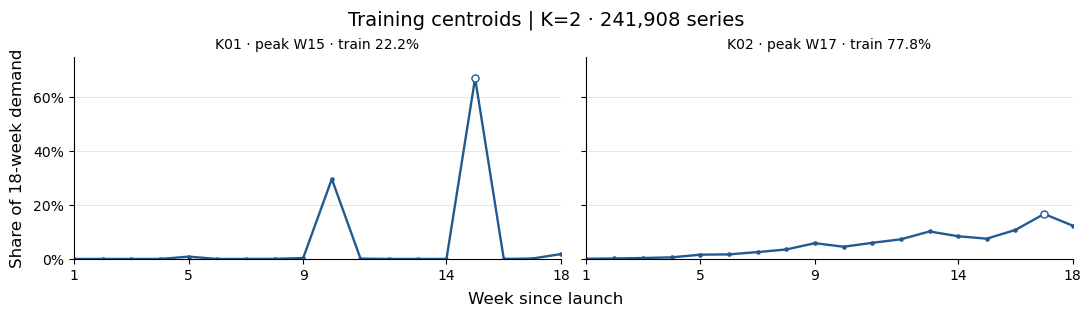

학습·검증 간 군집별 배정 비중 차이는 **최대 0.4%p**였다. 관측된 18주 수요를 같은 중심에 배정해 비교한 값이며, 출시 전 예측 정확도가 아니다.

In [11]:
import math

ncols = min(3, k_selected)
nrows = math.ceil(k_selected / ncols)
fig, panels = plt.subplots(
    nrows, ncols, squeeze=False, figsize=(10.8, nrows * 2.25 + 0.8),
    sharex=True, sharey=True, layout="constrained",
)
fig.suptitle(f"Training centroids | K={k_selected} · {len(x_train):,} series", fontsize=14)
fig.supxlabel("Week since launch")
fig.supylabel("Share of 18-week demand")
max_share = float(ordered_centers.max())
for axis, record, center in zip(panels.flat, cluster_rows, ordered_centers):
    axis.plot(weeks, center, color="#225a8f", marker="o", markersize=2.3, linewidth=1.7)
    peak = record["peak_week"]
    axis.scatter([peak], [center[peak - 1]], s=26, edgecolor="#225a8f", facecolor="white", zorder=3)
    axis.set_title(f"K{record['cluster']:02d} · peak W{peak} · train {record['train_share']:.1%}", fontsize=10)
    axis.set(xlim=(1, 18), ylim=(0, max_share * 1.12), xticks=[1, 5, 9, 14, 18])
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    axis.grid(axis="y", color="#dde4eb", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)
for axis in list(panels.flat)[k_selected:]:
    axis.set_visible(False)
for axis in panels.flat:
    if axis.get_visible():
        axis.tick_params(labelbottom=True)
plt.show()

max_gap = max(abs(r["validation_share"] - r["train_share"]) for r in cluster_rows) * 100
display(Markdown(
    f"학습·검증 간 군집별 배정 비중 차이는 **최대 {max_gap:.1f}%p**였다. "
    "관측된 18주 수요를 같은 중심에 배정해 비교한 값이며, 출시 전 예측 정확도가 아니다."
))

## 9. 대표 패턴 저장

`LTB_WRITE_KMEANS=1`로 실행하면 별도 폴더 `raw_data/ltb_new_product_profiles/kmeans_launch_date_v1/`에 분할·중심·최근접 군집·평가 지표를 저장한다. `LTB_KMEANS_OUTPUT_DIR`로 출력 폴더를 바꿀 수 있다. 기존 18주 파일은 덮어쓰지 않는다.

아래 신상품 예측에서는 **학습 표본의 군집 번호**를 정답으로 삼아 출시 시점에 알 수 있었던 속성으로만 프로파일 분류기를 학습한다. 검증 표본의 최근접 군집은 추후 비교할 정답이며 분류기의 입력이 아니다. 합성 수요가 대부분이므로 대표 패턴과 시기별 차이는 데이터 생성 방식과 함께 해석한다.

In [12]:
cluster_output = Path(os.environ.get("LTB_KMEANS_OUTPUT_DIR", str(data_dir / "kmeans_launch_date_v1")))
write_clusters = os.environ.get("LTB_WRITE_KMEANS", "0") == "1"

if write_clusters:
    if cluster_output.exists():
        raise FileExistsError(f"{cluster_output.name} 폴더가 이미 있습니다. 다른 경로를 지정하세요.")
    cluster_output.parent.mkdir(parents=True, exist_ok=True)
    split_assignments = profiles_for_cluster.drop(PROFILE_COLUMN)
    cluster_assignments = pl.concat([
        frame.select(KEY + ["launch_date", "label_available_on", "split"]).with_columns(
            pl.Series("cluster", labels), pl.Series("nearest_centroid_euclidean", distances),
        )
        for frame, labels, distances in [
            (train_set, train_labels, train_distance),
            (validation_set, validation_labels, validation_distance),
        ]
    ])
    with tempfile.TemporaryDirectory(prefix=".ltb_kmeans_", dir=cluster_output.parent) as tmp:
        stage = Path(tmp) / "dataset"
        stage.mkdir()
        outputs = {
            "split_assignments": split_assignments,
            "cluster_assignments": cluster_assignments,
            "centroids": pl.DataFrame(centroid_rows),
            "cluster_summary": pl.DataFrame(cluster_rows),
            "k_selection": metric_frame,
            "distance_summary": pl.DataFrame(distance_rows),
        }
        for name, frame in outputs.items():
            path = stage / f"{name}.parquet"
            frame.write_parquet(path, compression="zstd")
            assert pl.scan_parquet(path).select(pl.len()).collect().item() == frame.height
        details = {
            "source_profile": "sell_start_dt aligned, 18-week share vectors derived in this notebook",
            "source_master_sha256": manifest["master_parquet_sha256"],
            "source_detail_snapshot_at_utc": manifest["source_snapshot_at_utc"],
            "cutoff": CUTOFF.isoformat(), "label_maturity_weeks": HORIZON,
            "split_counts": split_counts, "shared_part_numbers": shared_part_numbers,
            "k_candidates": list(CANDIDATE_K), "selected_k": k_selected, "k_votes": winner["votes"],
            "k_tiebreak": "mean metric rank then smaller K",
            "train_screen_fit_size": len(fit_indices), "train_screen_score_size": len(score_indices),
            "final_fit_train_size": len(x_train), "restarts": RESTARTS, "seed": SEED,
            "scikit_learn": sklearn.__version__, "distance_metric": "euclidean",
            "files": {f"{name}.parquet": frame.height for name, frame in outputs.items()},
        }
        (stage / "manifest.json").write_text(json.dumps(details, indent=2) + "\n", encoding="utf-8")
        if cluster_output.exists():
            raise FileExistsError("Output directory appeared during execution.")
        stage.rename(cluster_output)
    print(f"저장 완료: {cluster_output.name} (산출물 {len(outputs)}개와 Manifest)")

## 10. 출시 정보로 수요를 예측하는 실험

[DemandForest 원 논문](https://research.utwente.nl/en/publications/forecasting-demand-profiles-of-new-products/)의 핵심인 **RF 패턴 분류 × QRF 18주 총수요**를 서비스 부품 데이터에 적용한다. 이 버전은 원 논문의 데이터·패키지·비교 실험을 그대로 재현하지 않는다. 분포 적합(Gamma/LogNormal), OneP 근접도 기준선, 재고 정책 시뮬레이션은 범위 밖이다.

- **입력:** 법인·사이트, 부품군, 제품 유형·그룹, 출시 월. 이력 수요, 품목번호, 마스터의 현재 상태·수요 통계, 출시 연도, 종료일은 모델 입력에서 제외한다. 이 마스터는 현재 추출본이므로 선택한 속성이 당시에도 같은 값이었는지는 증명할 수 없다.
- **정답:** 패턴 분류는 18주 총수요가 양수인 품목의 학습 군집 번호를 쓴다. 총수요와 주별 예측은 18주가 관측된 전부 0인 품목도 포함한다. 결측이나 음수가 있는 프로파일을 0으로 바꾸지 않는다.
- **분할:** 앞에서 정한 출시일 기준과 18주 마감 조건을 그대로 쓴다. 검증의 실제 수요와 군집 번호는 평가에만 쓴다. 다른 조직에 등장하지 않았던 품목번호의 결과도 따로 본다.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, cohen_kappa_score
from sklearn.preprocessing import OneHotEncoder

FEATURES = ["subs_cd", "site_cd", "part_fam_cd", "prod_type", "prod_grp", "launch_month"]
QUANTILES = (.05, .50, .95)
QRF_FIT_MAX = 40_000
QRF_TREES = 64
QRF_MIN_LEAF = 30
RF_TREES = 80
QA_SEED = SEED + 21

forecast_cohort = (
    pl.concat(forecast_input_pieces)
    .sort(["launch_date", *KEY])
    .with_columns(
        (pl.col("launch_week_start") + pl.duration(weeks=HORIZON)).cast(pl.Date).alias("label_available_on"),
        pl.col("launch_date").dt.month().cast(pl.String).alias("launch_month"),
    )
)
f_train = forecast_cohort.filter((pl.col("launch_date") < CUTOFF) & (pl.col("label_available_on") <= CUTOFF))
f_holdout = forecast_cohort.filter(pl.col("launch_date") >= CUTOFF)
assert f_train.select(pl.struct(KEY).n_unique()).item() == f_train.height
assert f_holdout.select(pl.struct(KEY).n_unique()).item() == f_holdout.height
assert f_train["label_available_on"].max() <= CUTOFF
assert f_train.select(KEY).join(f_holdout.select(KEY), on=KEY, how="inner").is_empty()
assert f_train.filter(pl.col("profile_status") == "ready").height == train_set.height
assert f_holdout.filter(pl.col("profile_status") == "ready").height == validation_set.height

train_targets = train_set.select(KEY).with_columns(pl.Series("profile_label", train_labels))
holdout_targets = validation_set.select(KEY).with_columns(pl.Series("profile_label", validation_labels))
f_train = f_train.join(train_targets, on=KEY, how="left", validate="1:1", maintain_order="left")
f_holdout = f_holdout.join(holdout_targets, on=KEY, how="left", validate="1:1", maintain_order="left")


def get_actual(frame):
    y = frame["weekly_actual"].list.to_array(HORIZON).to_numpy()
    assert y.shape == (frame.height, HORIZON)
    assert np.isfinite(y).all() and (y >= 0).all()
    assert np.array_equal(y.sum(axis=1) > 0, frame["profile_label"].is_not_null().to_numpy())
    return y


def get_features(frame):
    return frame.select(pl.col(FEATURES).cast(pl.String).fill_null("__MISSING__")).to_numpy()


encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
x_f_train = encoder.fit_transform(get_features(f_train))
x_f_holdout = encoder.transform(get_features(f_holdout))
y_f_train = get_actual(f_train)
y_f_holdout = get_actual(f_holdout)
total_train = y_f_train.sum(axis=1)
total_holdout = y_f_holdout.sum(axis=1)
positive_train = total_train > 0
positive_holdout = total_holdout > 0
class_train = f_train.filter(pl.col("profile_label").is_not_null())["profile_label"].to_numpy()
class_holdout = f_holdout.filter(pl.col("profile_label").is_not_null())["profile_label"].to_numpy()
has_seen_part = f_holdout["part_no"].is_in(f_train["part_no"].unique().implode()).to_numpy()
display(Markdown(
    f"총수요 학습 **{f_train.height:,}개**(전체 0수요 {int((~positive_train).sum()):,}), "
    f"검증 **{f_holdout.height:,}개**(전체 0수요 {int((~positive_holdout).sum()):,}). "
    f"검증 조직·품목 중 학습에 같은 품목번호가 없는 경우 **{int((~has_seen_part).sum()):,}개**."
))

총수요 학습 **258,000개**(전체 0수요 16,092), 검증 **92,000개**(전체 0수요 5,158). 검증 조직·품목 중 학습에 같은 품목번호가 없는 경우 **18,758개**.

### 모델 적합: Random Forest와 잎의 조건부 수요 분포

Random Forest 분류기에는 총량이 양수인 품목의 학습 군집 번호만 준다. 총량 모델은 학습 집합에서 고정 난수로 최대 40,000건을 뽑아 Mac에서 반복 가능하도록 한다. QRF는 각 트리의 **잎에 함께 들어간 학습 수요값**을 합친 가중 경험분포에서 평균과 P05·P50·P95를 구한다. 트리별 평균 예측값의 분위수를 구하는 방식과는 다르다. 각 트리의 가중치는 같고, 같은 잎에 들어간 전체 적합 표본에 동일한 잎 내 가중치를 준다.

In [14]:
"""Local leaf-weighted quantile forest for 18-week total demand."""

from dataclasses import dataclass

import numpy as np
from sklearn.ensemble import RandomForestRegressor


@dataclass(frozen=True)
class LeafQRF:
    forest: RandomForestRegressor
    target_values: np.ndarray
    # Dict per tree: leaf id -> (sorted target ranks in the leaf, normalized masses).
    leaves: tuple[dict[int, tuple[np.ndarray, np.ndarray]], ...]


def fit_leaf_qrf(X_train, y_train, *, seed, n_estimators=64, min_samples_leaf=30):
    """Fit splits with a bootstrap forest; route all fitting responses into its leaves.

    Within each reached leaf, fitting responses have equal weight; leaves from
    different trees are mixed with equal weight. This all-fitting-rows variant is
    distinct from both in-bag leaf weighting and quantiles of tree point predictions.
    """
    X_train = np.asarray(X_train, dtype=np.float32, order="C")
    y_train = np.asarray(y_train, dtype=np.float64)
    if (
        X_train.ndim != 2
        or y_train.ndim != 1
        or X_train.shape[0] != y_train.size
        or y_train.size == 0
    ):
        raise ValueError("Expected nonempty 2D X_train and aligned 1D y_train.")
    if not np.isfinite(X_train).all() or not np.isfinite(y_train).all():
        raise ValueError("The fitting matrix and responses must contain finite values.")

    forest = RandomForestRegressor(
        n_estimators=n_estimators,
        min_samples_leaf=min_samples_leaf,
        bootstrap=True,
        random_state=seed,
        n_jobs=2,
    ).fit(X_train, y_train)

    target_values, target_ranks = np.unique(y_train, return_inverse=True)
    routed = forest.apply(X_train)
    leaves = []
    for tree_leaves in routed.T:
        order = np.argsort(tree_leaves, kind="stable")
        sorted_leaves = tree_leaves[order]
        boundaries = np.r_[0, np.flatnonzero(np.diff(sorted_leaves)) + 1, y_train.size]
        leaf_map = {}
        for start, stop in zip(boundaries[:-1], boundaries[1:]):
            ranks, counts = np.unique(target_ranks[order[start:stop]], return_counts=True)
            leaf_map[int(sorted_leaves[start])] = (ranks, counts / (stop - start))
        leaves.append(leaf_map)

    return LeafQRF(forest, target_values, tuple(leaves))


def predict_leaf_qrf(model, X, quantiles=(0.05, 0.5, 0.95)):
    """Return conditional means and inverse empirical CDF quantiles, in input order."""
    X = np.asarray(X, dtype=np.float32, order="C")
    probabilities = np.asarray(quantiles, dtype=np.float64)
    if X.ndim != 2 or X.shape[1] != model.forest.n_features_in_:
        raise ValueError("X must be a 2D matrix with the fitted feature count.")
    if not np.isfinite(X).all():
        raise ValueError("X must contain only finite values.")
    if (
        probabilities.ndim != 1
        or not np.isfinite(probabilities).all()
        or np.any((probabilities < 0) | (probabilities > 1))
    ):
        raise ValueError("quantiles must be a 1D sequence of values in [0, 1].")
    if X.shape[0] == 0:
        return np.empty(0), np.empty((0, probabilities.size))

    unique_signatures, inverse = np.unique(model.forest.apply(X), axis=0, return_inverse=True)
    means = np.empty(unique_signatures.shape[0], dtype=np.float64)
    intervals = np.empty((unique_signatures.shape[0], probabilities.size), dtype=np.float64)
    target_values = model.target_values
    for row, signature in enumerate(unique_signatures):
        leaf_ranks, leaf_masses = zip(
            *(tree[int(leaf_id)] for tree, leaf_id in zip(model.leaves, signature))
        )
        # Every normalized leaf contributes total mass 1; global normalization
        # makes the mixture equivalent to assigning 1 / n_trees to each leaf.
        masses = np.bincount(
            np.concatenate(leaf_ranks),
            weights=np.concatenate(leaf_masses),
            minlength=target_values.size,
        )
        active = masses > 0
        support = target_values[active]
        weights = masses[active]
        cdf = np.cumsum(weights, dtype=np.longdouble)
        cdf /= cdf[-1]
        means[row] = np.sum(support * weights) / np.sum(weights)
        # Use the left inverse; allow tiny round-off on exact mass boundaries.
        locations = np.searchsorted(cdf, probabilities - 8 * np.finfo(float).eps, side="left")
        locations = np.minimum(locations, support.size - 1)
        locations[probabilities == 1] = support.size - 1
        intervals[row] = support[locations]

    return means[inverse], intervals[inverse]

In [15]:
classifier = RandomForestClassifier(
    n_estimators=RF_TREES, max_depth=12, min_samples_leaf=40,
    random_state=QA_SEED, n_jobs=THREADS,
)
qrf_rng = np.random.default_rng(QA_SEED)
qrf_indices = qrf_rng.choice(len(total_train), min(QRF_FIT_MAX, len(total_train)), replace=False)
with threadpool_limits(limits=THREADS):
    classifier.fit(x_f_train[positive_train], class_train)
    total_model = fit_leaf_qrf(
        x_f_train[qrf_indices], total_train[qrf_indices],
        seed=QA_SEED, n_estimators=QRF_TREES, min_samples_leaf=QRF_MIN_LEAF,
    )
    pred_class = classifier.predict(x_f_holdout)
    pred_total, total_quantiles = predict_leaf_qrf(total_model, x_f_holdout, quantiles=QUANTILES)

assert np.array_equal(classifier.classes_, np.arange(1, k_selected + 1))
assert np.all(np.diff(total_quantiles, axis=1) >= 0) and (total_quantiles >= 0).all()
assert np.isfinite(pred_total).all() and (pred_total >= 0).all()

# Direct training-member means remove tiny negative round-off from K-means centering.
forecast_centers = np.stack([x_train[train_labels == k].mean(axis=0) for k in range(1, k_selected + 1)])
np.testing.assert_allclose(forecast_centers, ordered_centers, atol=1e-9, rtol=0)
assert (forecast_centers >= 0).all()
predicted_shape = forecast_centers[pred_class - 1]
mean_train_weekly = y_f_train.mean(axis=0)
common_shape = mean_train_weekly / mean_train_weekly.sum()
plain_total_bounds = np.quantile(total_train, QUANTILES, method="inverted_cdf")
plain_weekly_bounds = np.quantile(y_f_train, QUANTILES, axis=0, method="inverted_cdf")
full_weekly = predicted_shape * pred_total[:, None]
fixed_shape_weekly = common_shape * pred_total[:, None]
full_low = predicted_shape * total_quantiles[:, 0, None]
full_high = predicted_shape * total_quantiles[:, 2, None]

np.testing.assert_allclose(full_weekly.sum(axis=1), pred_total, rtol=1e-9, atol=1e-9)
np.testing.assert_allclose(full_low.sum(axis=1), total_quantiles[:, 0], rtol=1e-9, atol=1e-9)
np.testing.assert_allclose(full_high.sum(axis=1), total_quantiles[:, 2], rtol=1e-9, atol=1e-9)
assert np.all(full_low <= full_high)
display(Markdown(f"RF 학습 **{len(class_train):,}개**, QRF 적합 표본 **{len(qrf_indices):,}개**."))

RF 학습 **241,908개**, QRF 적합 표본 **40,000개**.

## 11. 시간 기준 검증 결과

- **Train mean:** 모든 품목에 학습 주차 평균과 경험적 분위수를 적용하는 단순 기준선.
- **QRF + fixed shape:** 품목별 총량은 QRF로 예측하되, 주별 비중은 모든 품목에 공통인 학습 평균을 적용. 패턴 분류를 추가한 효과를 분리한다.
- **RF + QRF:** 분류기로 선택한 대표 비중과 품목별 총량을 곱한다. 검증용 실제 프로파일은 이 단계에서 사용하지 않는다.

두 QRF 모델의 주별 구간에는 **패턴이 틀릴 가능성이나 주별 변동성**이 반영되지 않는다. 90%는 총량에서 P05~P95를 뽑았다는 뜻이고, 실제로 포함한 비율은 아래에서 따로 확인한다. 오차는 반올림 전 수량으로 평가한다.

In [16]:
models_for_eval = {
    "Train mean": (
        np.broadcast_to(mean_train_weekly, y_f_holdout.shape),
        np.full(len(total_holdout), mean_train_weekly.sum()),
        np.broadcast_to(plain_total_bounds, total_quantiles.shape),
        np.broadcast_to(plain_weekly_bounds[0], y_f_holdout.shape),
        np.broadcast_to(plain_weekly_bounds[2], y_f_holdout.shape),
    ),
    "QRF + fixed shape": (
        fixed_shape_weekly, pred_total, total_quantiles,
        common_shape * total_quantiles[:, 0, None],
        common_shape * total_quantiles[:, 2, None],
    ),
    "RF + QRF": (full_weekly, pred_total, total_quantiles, full_low, full_high),
}


def record_metrics(model_name, mask, population):
    pred_w, pred_t, q_t, lo_w, hi_w = models_for_eval[model_name]
    y, y_total = y_f_holdout[mask], total_holdout[mask]
    dw = pred_w[mask] - y
    dt = pred_t[mask] - y_total
    denom = y_total.sum()
    assert len(y) and denom > 0
    return {
        "model": model_name, "population": population, "n": int(mask.sum()),
        "total_rmse": float(np.sqrt(np.mean(dt ** 2))),
        "total_bias": float(dt.sum() / denom),
        "weekly_wape": float(np.abs(dw).sum() / denom),
        "total_picp90": float(((y_total >= q_t[mask, 0]) & (y_total <= q_t[mask, 2])).mean()),
        "weekly_picp90": float(((y >= lo_w[mask]) & (y <= hi_w[mask])).mean()),
    }


populations = {"전체": np.ones(f_holdout.height, dtype=bool), "미등장 품목번호": ~has_seen_part}
metric_rows = [
    record_metrics(name, mask, population)
    for population, mask in populations.items() if mask.any()
    for name in models_for_eval
]
classification_rows = []
majority_train = int(np.bincount(class_train).argmax())
for population, mask in populations.items():
    selected = population == "전체" or mask.any()
    mask_pos = mask[positive_holdout]
    if not selected or not mask_pos.any():
        continue
    actual = class_holdout[mask_pos]
    for name, classified in [
        ("Train majority", np.full(len(actual), majority_train)),
        ("RF", pred_class[positive_holdout][mask_pos]),
    ]:
        classification_rows.append({
            "model": name, "population": population, "n": int(len(actual)),
            "accuracy": float(accuracy_score(actual, classified)),
            "balanced_accuracy": float(balanced_accuracy_score(actual, classified)),
            "kappa": float(cohen_kappa_score(actual, classified)),
        })

display(Markdown("\n".join([
    "| 검증 집합 | 패턴 분류 | 양수 품목 | 정확도 | 균형 정확도 | Kappa |",
    "|---|---|---:|---:|---:|---:|",
] + [
    f"| {r['population']} | {r['model']} | {r['n']:,} | {r['accuracy']:.1%} | "
    f"{r['balanced_accuracy']:.1%} | {r['kappa']:.3f} |" for r in classification_rows
])))
display(Markdown("\n".join([
    "| 검증 집합 | 예측 | 품목 수 | 총량 RMSE ↓ | 총량 편향 | 주별 WAPE ↓ | 총량 구간 적중률 | 주별 구간 적중률 |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
] + [
    f"| {r['population']} | {r['model']} | {r['n']:,} | {r['total_rmse']:,.1f} | {r['total_bias']:+.1%} | "
    f"{r['weekly_wape']:.1%} | {r['total_picp90']:.1%} | {r['weekly_picp90']:.1%} |" for r in metric_rows
])))

| 검증 집합 | 패턴 분류 | 양수 품목 | 정확도 | 균형 정확도 | Kappa |
|---|---|---:|---:|---:|---:|
| 전체 | Train majority | 86,842 | 77.4% | 50.0% | 0.000 |
| 전체 | RF | 86,842 | 97.3% | 94.1% | 0.920 |
| 미등장 품목번호 | Train majority | 17,624 | 86.5% | 50.0% | 0.000 |
| 미등장 품목번호 | RF | 17,624 | 98.2% | 93.2% | 0.917 |

| 검증 집합 | 예측 | 품목 수 | 총량 RMSE ↓ | 총량 편향 | 주별 WAPE ↓ | 총량 구간 적중률 | 주별 구간 적중률 |
|---|---|---:|---:|---:|---:|---:|---:|
| 전체 | Train mean | 92,000 | 31.4 | -5.1% | 120.2% | 94.8% | 96.1% |
| 전체 | QRF + fixed shape | 92,000 | 18.8 | +3.7% | 91.9% | 86.1% | 26.8% |
| 전체 | RF + QRF | 92,000 | 18.8 | +3.7% | 83.8% | 86.1% | 38.2% |
| 미등장 품목번호 | Train mean | 18,758 | 46.0 | -42.5% | 102.5% | 88.6% | 91.3% |
| 미등장 품목번호 | QRF + fixed shape | 18,758 | 28.7 | +4.5% | 84.7% | 87.4% | 36.1% |
| 미등장 품목번호 | RF + QRF | 18,758 | 28.7 | +4.5% | 83.7% | 87.4% | 40.9% |

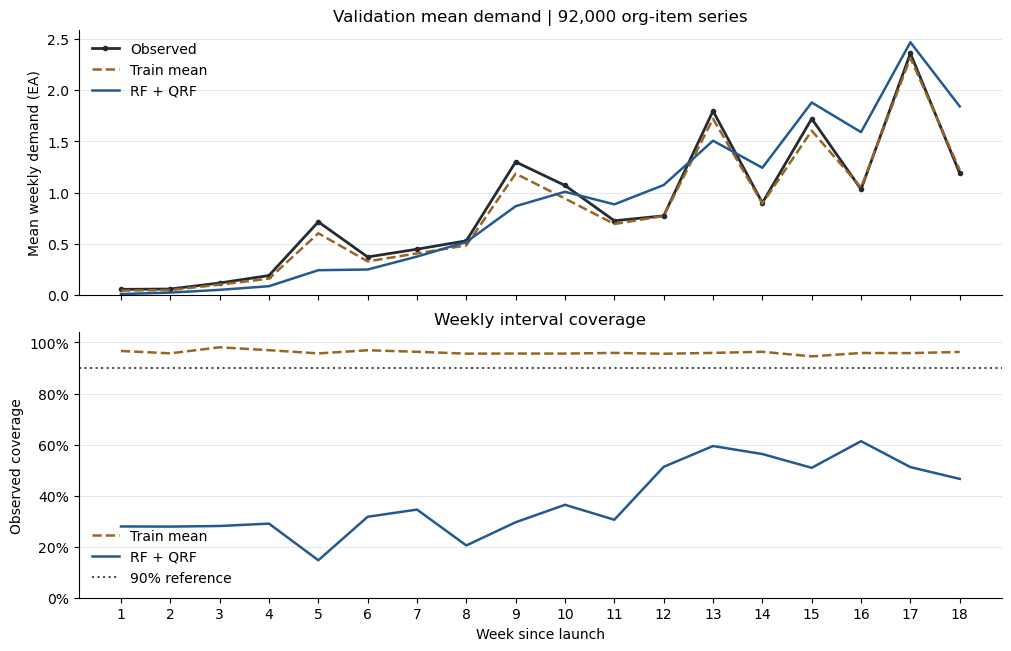

전체 검증에서 학습 평균 → RF + QRF의 18주 총량 RMSE는 **31.4 → 18.8**, 주별 WAPE는 **120.2% → 83.8%**였다. QRF에 패턴 분류를 추가했을 때 주별 WAPE는 **91.9% → 83.8%**였다. RF + QRF의 P05~P95 적중률은 총량 **86.1%**, 주별 **38.2%**다. 이 수치는 현재 속성 스냅샷과 대부분 합성인 수요에 대한 시간 기준 검증으로, 운영 성능을 보장하지 않는다.

In [17]:
fig, (ax, cover_ax) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, layout="constrained")
ax.plot(weeks, y_f_holdout.mean(axis=0), color="#252b33", linewidth=2, marker="o", markersize=3, label="Observed")
ax.plot(weeks, mean_train_weekly, color="#9a6523", linewidth=1.8, linestyle="--", label="Train mean")
ax.plot(weeks, full_weekly.mean(axis=0), color="#225a8f", linewidth=1.8, label="RF + QRF")
ax.set(title=f"Validation mean demand | {f_holdout.height:,} org-item series", ylabel="Mean weekly demand (EA)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", frameon=False)
for name, color, style in [("Train mean", "#9a6523", "--"), ("RF + QRF", "#225a8f", "-")]:
    _, _, _, lo, hi = models_for_eval[name]
    hit = ((y_f_holdout >= lo) & (y_f_holdout <= hi)).mean(axis=0)
    cover_ax.plot(weeks, hit, color=color, linestyle=style, linewidth=1.8, label=name)
cover_ax.axhline(.9, color="#454c54", linestyle=":", label="90% reference")
cover_ax.set(title="Weekly interval coverage", xlabel="Week since launch", ylabel="Observed coverage", ylim=(0, 1.04))
cover_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
cover_ax.legend(loc="lower left", frameon=False)
cover_ax.set_xticks(weeks)
for axis in (ax, cover_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#dde4eb", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

comparison = {r["model"]: r for r in metric_rows if r["population"] == "전체"}
baseline = comparison["Train mean"]
fixed = comparison["QRF + fixed shape"]
full = comparison["RF + QRF"]
display(Markdown(
    f"전체 검증에서 학습 평균 → RF + QRF의 18주 총량 RMSE는 **{baseline['total_rmse']:,.1f} → "
    f"{full['total_rmse']:,.1f}**, 주별 WAPE는 **{baseline['weekly_wape']:.1%} → "
    f"{full['weekly_wape']:.1%}**였다. QRF에 패턴 분류를 추가했을 때 주별 WAPE는 "
    f"**{fixed['weekly_wape']:.1%} → {full['weekly_wape']:.1%}**였다. "
    f"RF + QRF의 P05~P95 적중률은 총량 **{full['total_picp90']:.1%}**, 주별 **{full['weekly_picp90']:.1%}**다. "
    "이 수치는 현재 속성 스냅샷과 대부분 합성인 수요에 대한 시간 기준 검증으로, 운영 성능을 보장하지 않는다."
))

### 결과 파일

기본은 출력만 보며, `LTB_WRITE_LAUNCH_FORECAST=1`이면 `launch_demandforest_v1/`에 검증 예측·비교 지표·설정을 저장한다. 다른 경로는 `LTB_LAUNCH_FORECAST_OUTPUT_DIR`로 지정할 수 있다. 검증 자료의 실제값과 예측값은 구분해 저장한다.

In [18]:
write_launch_forecast = os.environ.get("LTB_WRITE_LAUNCH_FORECAST", "0") == "1"
launch_output = Path(os.environ.get("LTB_LAUNCH_FORECAST_OUTPUT_DIR", str(data_dir / "launch_demandforest_v1")))
if write_launch_forecast:
    if launch_output.exists():
        raise FileExistsError("기존 결과 폴더를 덮어쓰지 않습니다.")
    launch_output.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".launch_demandforest_", dir=launch_output.parent) as tmp:
        stage = Path(tmp) / "dataset"
        stage.mkdir()
        predictions = f_holdout.select(KEY + ["launch_date", "profile_label"]).with_columns(
            pl.Series("seen_part_no_in_train", has_seen_part),
            pl.Series("predicted_profile_label", pred_class),
            pl.Series("actual_total_18w", total_holdout),
            pl.Series("predicted_total_mean", pred_total),
            pl.Series("total_p05", total_quantiles[:, 0]),
            pl.Series("total_p50", total_quantiles[:, 1]),
            pl.Series("total_p95", total_quantiles[:, 2]),
            pl.Series("actual_weekly", y_f_holdout, dtype=pl.Array(pl.Float64, HORIZON)),
            pl.Series("forecast_weekly", full_weekly, dtype=pl.Array(pl.Float64, HORIZON)),
            pl.Series("weekly_p05", full_low, dtype=pl.Array(pl.Float64, HORIZON)),
            pl.Series("weekly_p95", full_high, dtype=pl.Array(pl.Float64, HORIZON)),
        )
        tables = {
            "validation_predictions": predictions, "forecast_metrics": pl.DataFrame(metric_rows),
            "classification_metrics": pl.DataFrame(classification_rows),
        }
        for name, df in tables.items():
            df.write_parquet(stage / f"{name}.parquet", compression="zstd")
            assert pl.scan_parquet(stage / f"{name}.parquet").select(pl.len()).collect().item() == df.height
        doc = {
            "source": EXTRACT_NAME, "source_snapshot_at": manifest["source_snapshot_at_utc"],
            "master_sha256": manifest["master_parquet_sha256"], "cutoff": CUTOFF.isoformat(),
            "horizon_weeks": HORIZON, "selected_k": k_selected, "features": FEATURES,
            "classification_train_size": len(class_train), "qrf_fit_size": len(qrf_indices),
            "total_train_size": f_train.height, "validation_size": f_holdout.height,
            "seed": QA_SEED, "qrf_trees": QRF_TREES, "qrf_min_samples_leaf": QRF_MIN_LEAF,
            "rf_trees": RF_TREES, "scikit_learn": sklearn.__version__,
            "quantiles": QUANTILES, "include_all_zero_in_total_model": True,
            "source_features_verified_as_of_launch": False,
            "files": {f"{name}.parquet": df.height for name, df in tables.items()},
        }
        (stage / "manifest.json").write_text(json.dumps(doc, indent=2) + "\n", encoding="utf-8")
        if launch_output.exists():
            raise FileExistsError("실행 중 결과 경로가 생성되어 중단합니다.")
        stage.rename(launch_output)
    print(f"저장 완료: {launch_output.name}")

저장 완료: launch_demandforest_v1
